# Categorización automática de un catálogo de retail a partir del nombre del producto
Proyecto individual · Aprendizaje de Máquina · Maestría en Ciencia de Datos (USFQ)

**Uso de IA.** El código de este notebook y del paquete `src/catalogo/` se escribió con
asistencia de Claude (Anthropic). Los prompts se citan como comentarios `# Prompt (IA):`
en las celdas donde se usaron; el prompt con el que se propusieron las etiquetas está en
la sección 2. El diseño completo y su plan están en `docs/superpowers/`.

In [1]:
# Prompt (IA): «Arma la celda de setup para que el notebook corra igual en Colab y en
# local: en Colab clona el repo y usa src/ sin pip install; fija la semilla.»
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    import os
    import subprocess
    subprocess.run(["git", "clone", "-q", "https://github.com/xGerart/ml-catalogo-pladsh.git"], check=False)
    os.chdir("ml-catalogo-pladsh")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "wordcloud"], check=True)
sys.path.insert(0, str(Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent) + "/src")

import json
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import (
    GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict, train_test_split,
)
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from wordcloud import WordCloud

from catalogo import SEED
from catalogo.data import find_root
from catalogo.evaluation import (
    classification_metrics, corrected_resampled_ttest, plot_learning_curve, plot_param_curve,
    plot_roc_multiclass, plot_tsne, repeated_cv_scores, wilcoxon_test,
)
from catalogo.features import MeanEmbeddingVectorizer, tokenize, vocabulary_coverage
from catalogo.labeling import load_labeled

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="k=.*is greater than n_features")
ROOT = find_root()
FIG = ROOT / "reports/figures"
W2V = str(ROOT / "data/processed/w2v_vocab.npz")
np.random.seed(SEED)

## 1. Introducción

**Contexto.** Una tienda de productos de belleza en Ecuador opera con un ERP propio. De
sus **11 296 productos, 10 697 (95 %) están en la categoría comodín «General»**: se
cargaron desde el sistema anterior sin categoría. Las ~600 que sí la tienen son todas
capilares (Shampoo, Mascarilla, Matizantes…), pero el catálogo incluye uñas,
maquillaje, pestañas, skincare, herramientas y accesorios.

**Por qué importa.** Sin categoría no hay reportes de ventas por rubro, ni análisis de
margen por línea, ni reglas de reposición por familia de producto. Categorizar 10 697
productos a mano es inviable, y el único dato disponible de cada uno es su **nombre**:
texto corto (≈5 palabras), en mayúsculas, con abreviaturas («ESM UV LED #12 12ML»),
marcas y códigos.

**Qué se hace.** Se plantea como **clasificación supervisada multiclase de texto
corto**: (1) se define una taxonomía de 8 macro-categorías; (2) se etiqueta una muestra
aleatoria de 1 000 productos; (3) se comparan dos técnicas —**TF-IDF de n-gramas de
caracteres + χ² + regresión logística** contra **Word2Vec preentrenado + SVM**—, con
optimización de hiperparámetros por validación cruzada repetida y un **test de
Wilcoxon** para decidir si la diferencia es estadísticamente significativa; (4) se
aplica el mejor modelo a los 9 777 productos restantes, con un umbral de confianza que
separa lo que se categoriza solo de lo que necesita revisión manual.

In [2]:
df = load_labeled(ROOT / "data/processed/productos_etiquetados.csv")
resumen = json.loads((ROOT / "etiquetado/resumen.json").read_text())
resumen

{'revisados': 1000,
 'excluidos_no_se': 0,
 'etiquetados': 1000,
 'corregidos': 4,
 'pct_corregidos': 0.4,
 'fusionadas_en_otros': ['Extensiones y accesorios de cabello'],
 'distribucion': {'Uñas': 318,
  'Cuidado capilar': 150,
  'Maquillaje': 136,
  'Coloración capilar': 118,
  'Otros': 84,
  'Piel y cuerpo': 76,
  'Pestañas y cejas': 66,
  'Herramientas y equipos de cabello': 52},
 'control_capilar': {'productos': 61,
  'propuesta_capilar_pct': 96.72,
  'final_capilar_pct': 96.72,
  'fuera_de_capilar': [{'id': 474,
    'nombre': 'BIOAQUA RICE RAW PULP 70ML',
    'categoria': 'Aceite',
    'final': 'Piel y cuerpo'},
   {'id': 430,
    'nombre': 'DBELESA GOTAS DE NVIDIA 30ML',
    'categoria': 'Serum',
    'final': 'Piel y cuerpo'}]}}

## 2. Datos y etiquetado

**Origen.** Export de solo lectura del ERP en producción (2026-10-06). Solo se usan
`id` y `nombre`; precio, ventas y código de barras se descartaron a propósito: las
ventas no dicen qué *es* un producto y un producto nuevo no las tiene; el código de
barras es un identificador arbitrario.

**Deduplicado.** 506 nombres estaban repetidos. Se normalizaron (mayúsculas, espacios)
y se dejó uno por nombre **antes** de muestrear: si el mismo texto cae en
entrenamiento y en test, la métrica sale inflada (*data leakage*). Quedan 10 777
productos únicos.

**Taxonomía.** Se exploró con k-means sobre n-gramas de caracteres
(`notebooks/01_eda_taxonomia.ipynb`). Hallazgo: los clústeres agrupan por **marca**
(ITELY, ALFAPARF, COQUETAS) y no por tipo de producto (silhouette 0,02–0,04), así que
la taxonomía se definió con criterio humano por *para qué sirve* el producto
(`etiquetado/taxonomia.md`). Ese mismo hallazgo justifica un modelo supervisado.

**Muestra y etiquetado asistido.** 1 000 productos al azar (semilla 42) del catálogo
deduplicado. Un LLM propuso una etiqueta por producto con un prompt fijo
(`etiquetado/prompt_etiquetado.md`, reproducido abajo) y el autor revisó las 1 000 en
una planilla: **corrigió 4 (0,4 %)**, todas cosmetiqueras y maletines que pasaron de
«Otros» a «Maquillaje».

**Control externo.** 61 productos de la muestra ya tenían categoría en el ERP (puesta
por personal de la tienda). El 96,7 % quedó en una categoría capilar, como corresponde;
los 2 restantes («BIOAQUA RICE RAW PULP», «DBELESA GOTAS…») son de skincare y el ERP los
tenía como «Aceite» y «Serum».

**Clase fusionada.** «Extensiones y accesorios de cabello» tuvo 28 ejemplos, menos que
el mínimo de 30 fijado antes de etiquetar, y se fusionó en «Otros». Quedan **8 clases**.

In [3]:
print((ROOT / "etiquetado/prompt_etiquetado.md").read_text())

# Prompt usado para proponer etiquetas (Claude, Anthropic)

Eres un experto en productos de belleza y cuidado personal de una tienda en Ecuador.
Clasifica cada producto en UNA de estas categorías, usando solo su nombre:

- Uñas: esmaltes, geles, acrílicos, monómeros, uñas postizas, decoración, limas, lámparas UV/LED y removedores para manicure/pedicure.
- Cuidado capilar: shampoo, acondicionador, mascarilla capilar, tratamientos, ampollas, aceites y óleos, termoprotectores, alisados/keratina, ceras y geles de peinado; incluye matizantes de cuidado (shampoo o mascarilla matizante).
- Coloración capilar: tintes, oxidantes/oxigentas, reveladores, decolorantes y colorantes de fantasía.
- Maquillaje: bases, correctores, polvos, rubores, iluminadores, sombras, delineadores, labiales, primers y fijadores; incluye brochas y esponjas de maquillaje.
- Pestañas y cejas: pestañas postizas y de extensión, pegamentos, lifting y laminado, accesorios para su aplicación.
- Piel y cuerpo: skincare facia

## 3. Análisis exploratorio (EDA)

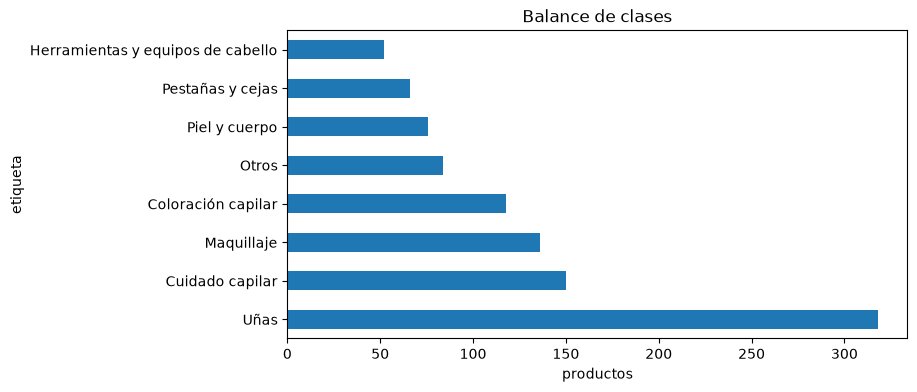

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
df["etiqueta"].value_counts().plot.barh(ax=ax)
ax.set_title("Balance de clases")
ax.set_xlabel("productos")
fig.savefig(FIG / "balance.png", bbox_inches="tight")

**¿Está balanceada?** No. «Uñas» tiene 318 ejemplos y «Herramientas y equipos de
cabello» 52: una razón de 6 a 1. Consecuencias que se aplican en todo el notebook:
(1) la métrica de optimización es **F1-macro**, que pesa igual a todas las clases (la
accuracy premiaría acertar solo «Uñas»); (2) todos los splits y la validación cruzada
son **estratificados**, para que cada fold conserve la proporción de clases.

Palabras por nombre: media 4.94, mediana 5.0, skewness 1.66


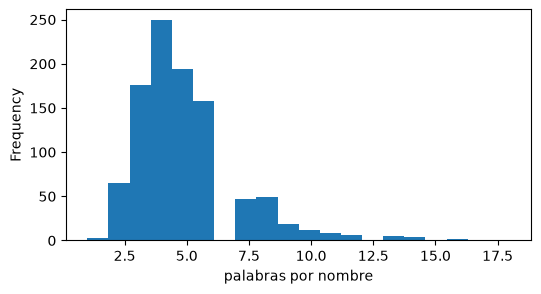

In [5]:
largo = df["nombre"].str.split().str.len()
print(f"Palabras por nombre: media {largo.mean():.2f}, mediana {largo.median()}, skewness {largo.skew():.2f}")
fig, ax = plt.subplots(figsize=(6, 3))
largo.plot.hist(bins=20, ax=ax)
ax.set_xlabel("palabras por nombre")
fig.savefig(FIG / "largo_nombres.png", bbox_inches="tight")

**¿Está normalizada? ¿Hace falta una transformación no lineal?** El largo de los
nombres tiene asimetría positiva (skewness ≈ 1,66): la mayoría tiene 4–6 palabras y
unos pocos son descripciones largas. **No se transforma** porque el largo no entra como
feature. Lo que sí se normaliza es la representación: TF-IDF con `sublinear_tf`
(log de la frecuencia) y normalización L2 por documento; los vectores Word2Vec se
estandarizan con `StandardScaler` porque el kernel RBF del SVM depende de distancias.
**¿Estacionalidad?** No aplica: no es una serie de tiempo.

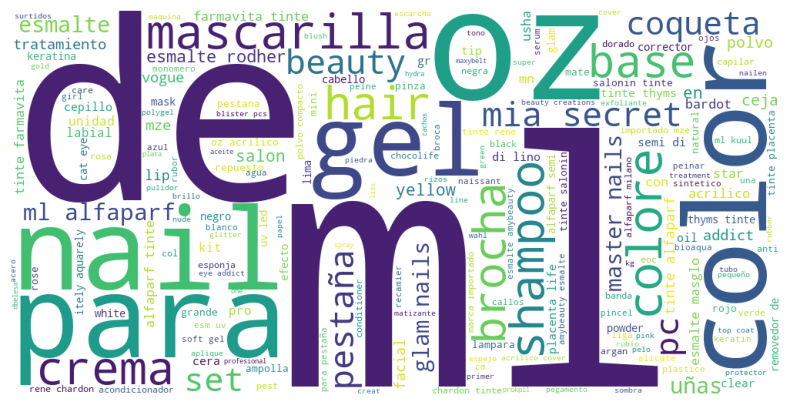

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
wc = WordCloud(width=1000, height=500, background_color="white", random_state=SEED)
ax.imshow(wc.generate(" ".join(t for n in df["nombre"] for t in tokenize(n))))
ax.axis("off")
fig.savefig(FIG / "wordcloud.png", bbox_inches="tight")

In [7]:
top = {
    cat: Counter(t for n in grupo["nombre"] for t in tokenize(n)).most_common(8)
    for cat, grupo in df.groupby("etiqueta")
}
pd.DataFrame({c: [f"{w} ({n})" for w, n in ws] for c, ws in top.items()})

,Coloración capilar,Cuidado capilar,Herramientas y equipos de cabello,Maquillaje,Otros,Pestañas y cejas,Piel y cuerpo,Uñas
0,tinte (72),ml (87),mze (9),polvo (17),de (24),pestañas (20),ml (20),esmalte (58)
1,ml (26),shampoo (21),de (7),de (14),colores (9),de (18),de (14),nails (56)
2,alfaparf (25),mascarilla (17),star (6),pcs (13),mze (6),glam (10),facial (10),de (42)
3,color (14),de (15),cepillo (5),brocha (13),ligas (5),para (9),crema (9),oz (30)
4,thyms (12),hair (14),wahl (5),vogue (12),star (4),beauty (8),mascarilla (8),ml (28)
5,farmavita (12),tratamiento (14),marca (5),labial (11),rulos (4),pest (7),bioaqua (6),gel (28)
6,itely (9),yellow (14),barbero (4),beauty (10),ml (3),satine (7),exfoliante (5),acrilico (25)
7,aquarely (9),alfaparf (13),capa (4),liquido (10),acero (3),pestana (6),beauty (5),addict (22)


**Palabras frecuentes.** Cada clase tiene palabras muy distintivas («esmalte», «nails»,
«gel», «acrilico» en Uñas; «tinte», «color» en Coloración) y **marcas** que casi
definen la clase (alfaparf, thyms, farmavita en Coloración). Las unidades («ml», «oz»)
y conectores («de», «para») aparecen en todas y aportan poco; TF-IDF les baja el peso
solo por aparecer en muchos documentos.

In [8]:
words = set(np.load(W2V)["words"].tolist())
cov = vocabulary_coverage(df["nombre"].tolist(), words)
cov

{'tokens_total': 4482,
 'tokens_sin_vector': 519,
 'pct_tokens_sin_vector': 11.58,
 'productos_sin_vector': 4,
 'pct_productos_sin_vector': 0.4,
 'top_sin_vector': [('alfaparf', 39),
  ('rodher', 18),
  ('amybeauty', 15),
  ('masglo', 14),
  ('thyms', 12),
  ('farmavita', 12),
  ('salonin', 11),
  ('itely', 9),
  ('aquarely', 9),
  ('kuul', 9),
  ('chocolife', 7),
  ('naissant', 6),
  ('bioaqua', 6),
  ('monomero', 6),
  ('kolinsky', 6),
  ('nailen', 5),
  ('polygel', 5),
  ('vogle', 5),
  ('maxybelt', 4),
  ('matizante', 4)]}

**Cobertura de Word2Vec.** El 11,6 % de las palabras del dataset no tiene vector
preentrenado, y solo 4 productos (0,4 %) quedan sin ninguna. Pero las palabras sin
vector **son justamente las marcas** (alfaparf, rodher, amybeauty, masglo, thyms…): el
modelo preentrenado se construyó con texto general en español y nunca las vio. Esto
anticipa la principal debilidad de la técnica 2.

## 4. Feature extraction

**Técnica 1 — TF-IDF de n-gramas de caracteres** (opción 1 de la rúbrica). Se usan
n-gramas de *caracteres* (`char_wb`) y no de palabras porque los nombres están llenos
de abreviaturas y errores de tipeo: «ESM», «ESMALTE», «ESAMALTE» y «ESMALETE» comparten
los fragmentos «esm» y «sma», mientras que como palabras serían cuatro features sin
relación. `min_df=2` descarta n-gramas que aparecen en un solo nombre (ruido).

**Técnica 2 — Word2Vec preentrenado** (opción 2 de la rúbrica: transfer learning),
sugerencia del docente. Vectores de 300 dimensiones del *Spanish Billion Words Corpus*
[1], entrenados con Word2Vec [2]. El vector de un producto es el **promedio** de los
vectores de sus palabras. Ventaja esperada: semejanza semántica («mascarilla» cerca de
«tratamiento») aunque no compartan letras. Como el modelo completo pesa 1,1 GB, se
recortó al vocabulario del catálogo (`scripts/extraer_vocab_w2v.py`, con verificación
SHA-256 del archivo descargado).

In [9]:
# Vecinos más cercanos en el espacio Word2Vec: muestran qué "sabe" el modelo preentrenado.
data = np.load(W2V)
vocab, V = data["words"].tolist(), data["vectors"]
Vn = V / np.linalg.norm(V, axis=1, keepdims=True)
pd.DataFrame({
    q: [vocab[i] for i in (Vn @ Vn[vocab.index(q)]).argsort()[::-1][1:7]]
    for q in ["esmalte", "tinte", "pestañas", "labial", "shampoo"]
})

,esmalte,tinte,pestañas,labial,shampoo
0,esmaltes,tintes,rizador,labiales,pedicure
1,pigmento,teñido,cejas,delineadores,manicure
2,esmaltada,matiz,delineadores,labios,shave
3,laca,tono,labios,eyeliner,rinse
4,alisadora,nacarado,postizas,lapiz,desodorantes
5,decolorar,humecta,ojeras,rimel,jabon


Los vecinos tienen sentido en general («pestañas» → rizador, cejas, postizas), pero
también muestran ruido del corpus general («shampoo» → pedicure, manicure).

## 5. Feature selection

Se usa **χ² (tipo filtro)** sobre TF-IDF: puntúa cada n-grama según su dependencia
con la clase, sin entrenar un modelo, y se quedan los *k* mejores. *k* entra a la
grilla de hiperparámetros, así que la selección se optimiza con la misma validación
cruzada. **No se aplica a Word2Vec**: χ² exige features no negativas y los promedios de
Word2Vec toman valores negativos; además, la representación preentrenada ya es densa y
de baja dimensión (300), como admite la rúbrica para transfer learning.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    df["nombre"], df["etiqueta"], test_size=0.2, stratify=df["etiqueta"], random_state=SEED
)
len(X_train), len(X_test)

(800, 200)

**Split.** 80 % entrenamiento (800) / 20 % test (200), estratificado. El test **no se
toca** hasta la sección 8: toda decisión (hiperparámetros, comparación) se toma con
validación cruzada sobre el 80 %.

## 6. Pipelines

Cada técnica es un `Pipeline` de sklearn: la extracción de features se ajusta **dentro
de cada fold** de la validación cruzada. Si TF-IDF o χ² se ajustaran con todos los
datos antes de la CV, verían los folds de validación (data leakage).

In [11]:
# Prompt (IA): «Define los dos pipelines de sklearn: TF-IDF char_wb → SelectKBest(chi2)
# → LogisticRegression, y MeanEmbeddingVectorizer → StandardScaler → SVC RBF con
# probability=True para poder calcular AUC.»
pipe_tfidf = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer="char_wb", sublinear_tf=True, min_df=2)),
    ("chi2", SelectKBest(chi2)),
    ("clf", LogisticRegression(max_iter=3000)),
])
pipe_w2v = Pipeline([
    ("w2v", MeanEmbeddingVectorizer(W2V)),
    ("scaler", StandardScaler()),
    ("clf", SVC(kernel="rbf", probability=True, random_state=SEED)),
])

## 7. Optimización de hiperparámetros

Búsqueda en grilla con **repeated stratified k-fold (5 folds × 3 repeticiones)** sobre
el 80 % de entrenamiento, métrica F1-macro. Se usan 5 folds (y no 10) para el *tuning*
porque cada combinación de la grilla se entrena 15 veces; las 10 × 10 se reservan para
la comparación final. No se usa nested CV, como recomienda la rúbrica.

| Técnica | Hiperparámetro | Valores | Por qué |
|---|---|---|---|
| TF-IDF + LogReg | `C = 1/λ` | 10⁻² … 10⁴ (10 valores log) | fuerza de la regularización L2; escala log porque su efecto es multiplicativo |
| | `k` de χ² | 250, 500, 1000, 2000, 3500, `all` | cuántos n-gramas conservar; `all` = sin selección, para medir si χ² aporta |
| | rango de n-gramas | (2, 4), (2, 5) | largo de los fragmentos de texto |
| Word2Vec + SVM | `C` | 10⁻² … 10³ (8 valores log) | penalización de errores del SVM |
| | `γ` | `scale`, 10⁻³, 10⁻² | ancho del kernel RBF |

In [12]:
# Prompt (IA): «Optimiza ambos pipelines con GridSearchCV y RepeatedStratifiedKFold
# 5×3, scoring f1_macro; para LogReg grilla de C en escala log, k de chi2 y ngram_range.»
cv_tune = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
grid_tfidf = {
    "tfidf__ngram_range": [(2, 4), (2, 5)],
    "chi2__k": [250, 500, 1000, 2000, 3500, "all"],  # "all" = sin selección, para comparar
    "clf__C": np.logspace(-2, 4, 10),  # C = 1/λ; hasta 10⁴ para que el óptimo no caiga en el borde
}
grid_w2v = {"clf__C": np.logspace(-2, 3, 8), "clf__gamma": ["scale", 1e-3, 1e-2]}
search_tfidf = GridSearchCV(pipe_tfidf, grid_tfidf, cv=cv_tune, scoring="f1_macro", n_jobs=-1).fit(X_train, y_train)
search_w2v = GridSearchCV(pipe_w2v, grid_w2v, cv=cv_tune, scoring="f1_macro", n_jobs=-1).fit(X_train, y_train)
search_tfidf.best_params_, search_tfidf.best_score_, search_w2v.best_params_, search_w2v.best_score_

({'chi2__k': 'all',
  'clf__C': np.float64(464.1588833612773),
  'tfidf__ngram_range': (2, 5)},
 np.float64(0.7387081738190697),
 {'clf__C': np.float64(7.196856730011521), 'clf__gamma': 0.001},
 np.float64(0.6404174684967547))

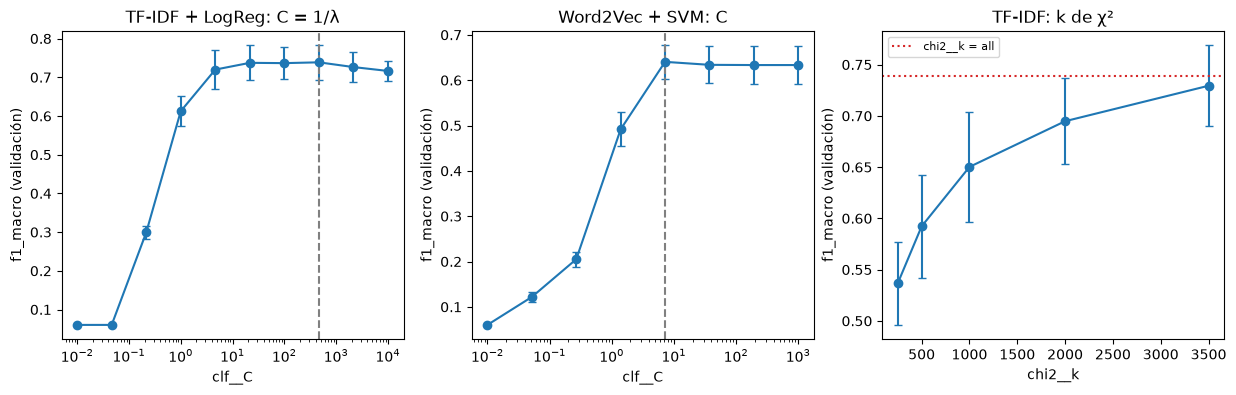

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_param_curve(search_tfidf, "clf__C", axes[0])
axes[0].set_title("TF-IDF + LogReg: C = 1/λ")
plot_param_curve(search_w2v, "clf__C", axes[1])
axes[1].set_title("Word2Vec + SVM: C")
plot_param_curve(search_tfidf, "chi2__k", axes[2], log=False)
axes[2].set_title("TF-IDF: k de χ²")
fig.savefig(FIG / "optimizacion.png", bbox_inches="tight")

**Lectura de la optimización.**
- **C = 1/λ (LogReg).** Con C ≤ 0,05 (λ grande) el modelo está sobre-regularizado:
  F1-macro ≈ 0,06, predice una sola clase (**subajuste**). El desempeño sube hasta
  estabilizarse en C ≈ 5–500 y cae levemente en C = 10⁴ (λ casi cero: el modelo
  empieza a sobreajustar). Óptimo: **C ≈ 464**, F1-macro de validación ≈ 0,739. Que el
  óptimo prefiera poca regularización es coherente con features muy distintivas.
- **C (SVM).** Mismo patrón; óptimo **C ≈ 7,2 con γ = 10⁻³**, F1-macro ≈ 0,640, con
  una meseta a la derecha.
- **k de χ².** El F1 sube de forma monótona con k (0,54 con k = 250 → 0,73 con
  k = 3500) y el mejor resultado es **sin selección** (línea roja, `all`: 0,739). La
  diferencia entre k = 3500 y `all` (0,009) es menor que la desviación estándar entre
  folds (≈ 0,04): **χ² no aporta**. La regresión logística regularizada ya asigna peso
  casi cero a los n-gramas irrelevantes. Es un resultado, no un error: se probó la
  selección contra la ausencia de selección y los datos dicen que conviene conservar
  todos los n-gramas.

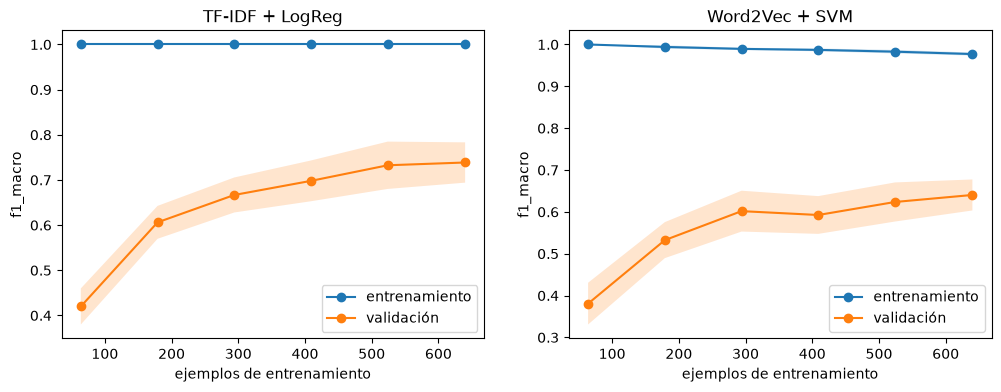

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_learning_curve(search_tfidf.best_estimator_, X_train, y_train, cv_tune, axes[0], title="TF-IDF + LogReg")
plot_learning_curve(search_w2v.best_estimator_, X_train, y_train, cv_tune, axes[1], title="Word2Vec + SVM")
fig.savefig(FIG / "curvas_aprendizaje.png", bbox_inches="tight")

**Diagnóstico sesgo vs. varianza.** En ambas técnicas el F1 de entrenamiento es ≈ 1 y
el de validación queda muy por debajo (≈ 0,74 y ≈ 0,64), con una brecha grande:
**alta varianza**. La curva de validación **sigue subiendo** al llegar a 640 ejemplos y
no se ha estabilizado: **más datos etiquetados mejorarían el modelo**. Es la acción con
mejor retorno (más que cambiar de algoritmo), y es barata gracias al etiquetado
asistido. Word2Vec + SVM además tiene un techo más bajo: su problema no es solo de
varianza sino de representación (no conoce las marcas).

## 8. Comparación estadística: Wilcoxon sobre repeated stratified 10 × 10 CV

Los dos modelos ya optimizados se evalúan con **los mismos 100 folds**
(`RepeatedStratifiedKFold`, 10 folds × 10 repeticiones, `random_state=42`). Se usa
validación **estratificada** porque las clases están desbalanceadas: un fold sin
ejemplos de «Herramientas» daría un F1-macro sin sentido. Como cada fold produce un par
de scores (uno por modelo), el test es **pareado**: Wilcoxon de rangos con signo [4],
que no asume normalidad de las diferencias.

- H₀: las diferencias de F1-macro entre ambos modelos son simétricas alrededor de 0
  (ninguno es sistemáticamente mejor).
- H₁: no lo son. α = 0,05.

**Limitaciones y cómo se tratan.** (1) Los 100 scores **no son independientes**: los
folds comparten datos, así que la varianza de las diferencias se subestima y el
p-value de Wilcoxon sale optimista. Por eso se reporta además el **t-test corregido de
Nadeau y Bengio** [8], que infla esa varianza por (1/J + n_test/n_train) y es el
estándar para comparar modelos con CV repetida. (2) La comparación usa los mismos 800
ejemplos con los que se optimizaron los hiperparámetros, y la grilla de TF-IDF (120
combinaciones) es más grande que la de Word2Vec (24): el sesgo de selección favorece
levemente a TF-IDF. El test de la sección siguiente, con 200 productos nunca vistos,
controla ese sesgo.

F1-macro medio: TF-IDF + LogReg 0.759 · Word2Vec + SVM 0.648
Wilcoxon: estadístico 37, p = 1.18e-17
t corregido (Nadeau–Bengio): t = 4.87, p = 4.30e-06


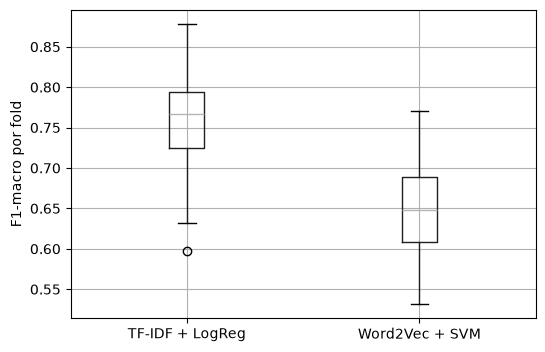

In [15]:
# Prompt (IA): «Compara los dos mejores modelos con repeated stratified 10x10 CV usando
# los mismos folds y aplica Wilcoxon pareado con alpha 0.05; grafica la distribución.»
N_SPLITS, N_REPEATS = 10, 10  # bajar a 5, 2 si tarda > ~15 min en Colab (permitido por la rúbrica)
scores = repeated_cv_scores(
    {"TF-IDF + LogReg": search_tfidf.best_estimator_, "Word2Vec + SVM": search_w2v.best_estimator_},
    X_train, y_train, n_splits=N_SPLITS, n_repeats=N_REPEATS,
)
res = wilcoxon_test(scores, "TF-IDF + LogReg", "Word2Vec + SVM")
n_test_fold = len(X_train) // N_SPLITS
res_nb = corrected_resampled_ttest(
    scores, "TF-IDF + LogReg", "Word2Vec + SVM", n_train=len(X_train) - n_test_fold, n_test=n_test_fold
)
fig, ax = plt.subplots(figsize=(6, 4))
scores.boxplot(ax=ax)
ax.set_ylabel("F1-macro por fold")
fig.savefig(FIG / "comparacion.png", bbox_inches="tight")
print(f"F1-macro medio: TF-IDF + LogReg {res['media_a']:.3f} · Word2Vec + SVM {res['media_b']:.3f}")
print(f"Wilcoxon: estadístico {res['estadistico']:.0f}, p = {res['p_value']:.2e}")
print(f"t corregido (Nadeau–Bengio): t = {res_nb['t']:.2f}, p = {res_nb['p_value']:.2e}")

**Resultado.** F1-macro medio en los 100 folds: **0,759 (TF-IDF + LogReg)** contra
**0,648 (Word2Vec + SVM)**. Wilcoxon: **p ≈ 1,2 × 10⁻¹⁷**; t corregido de
Nadeau–Bengio: **t = 4,87, p ≈ 4,3 × 10⁻⁶**. Ambos < 0,05: se rechaza H₀ y la ventaja
de TF-IDF + LogReg es estadísticamente significativa. El p corregido es once órdenes de
magnitud mayor que el de Wilcoxon —eso es lo que cuesta la dependencia entre folds—,
pero la conclusión se mantiene.

### Métricas en el conjunto de test (200 productos nunca vistos)

,TF-IDF + LogReg,Word2Vec + SVM
accuracy,0.825,0.695
precision_macro,0.794,0.663
recall_macro,0.727,0.572
f1_macro,0.750,0.582
f1_weighted,0.814,0.676
auc_macro,0.973,0.910
auc_micro,0.982,0.935


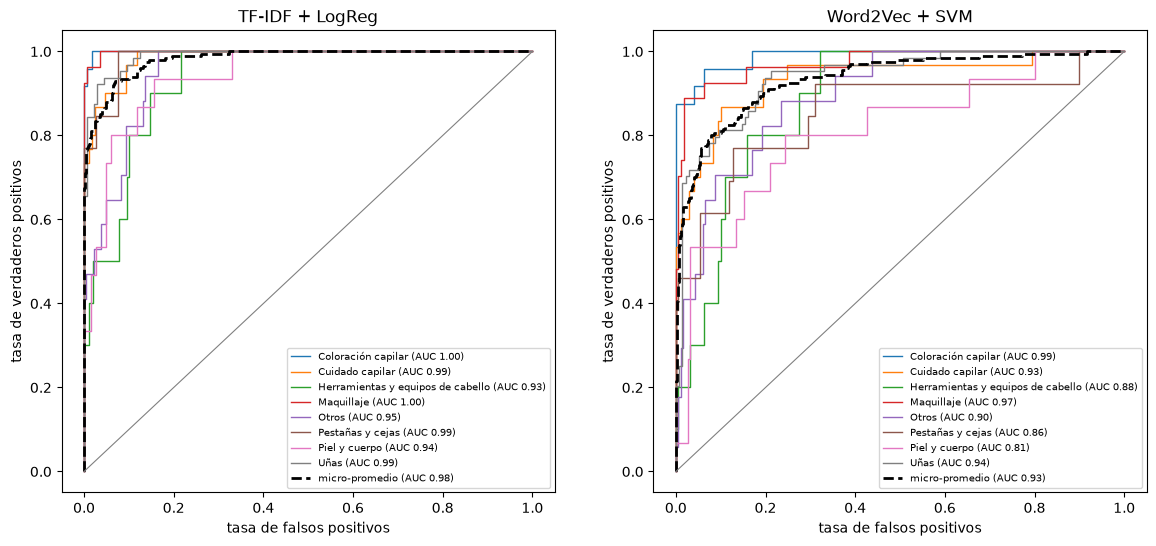

In [16]:
filas = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, search) in zip(axes, [("TF-IDF + LogReg", search_tfidf), ("Word2Vec + SVM", search_w2v)]):
    est = search.best_estimator_
    proba = est.predict_proba(X_test)
    filas[name] = classification_metrics(y_test, est.predict(X_test), proba, est.classes_)
    plot_roc_multiclass(y_test, proba, est.classes_, ax, title=name)
fig.savefig(FIG / "roc.png", bbox_inches="tight")
pd.DataFrame(filas).round(3)

                                   precision    recall  f1-score   support

               Coloración capilar       1.00      0.92      0.96        24
                  Cuidado capilar       0.76      0.87      0.81        30
Herramientas y equipos de cabello       0.67      0.40      0.50        10
                       Maquillaje       0.96      0.96      0.96        27
                            Otros       0.64      0.53      0.58        17
                 Pestañas y cejas       0.83      0.77      0.80        13
                    Piel y cuerpo       0.67      0.40      0.50        15
                             Uñas       0.82      0.97      0.89        64

                         accuracy                           0.82       200
                        macro avg       0.79      0.73      0.75       200
                     weighted avg       0.82      0.82      0.81       200



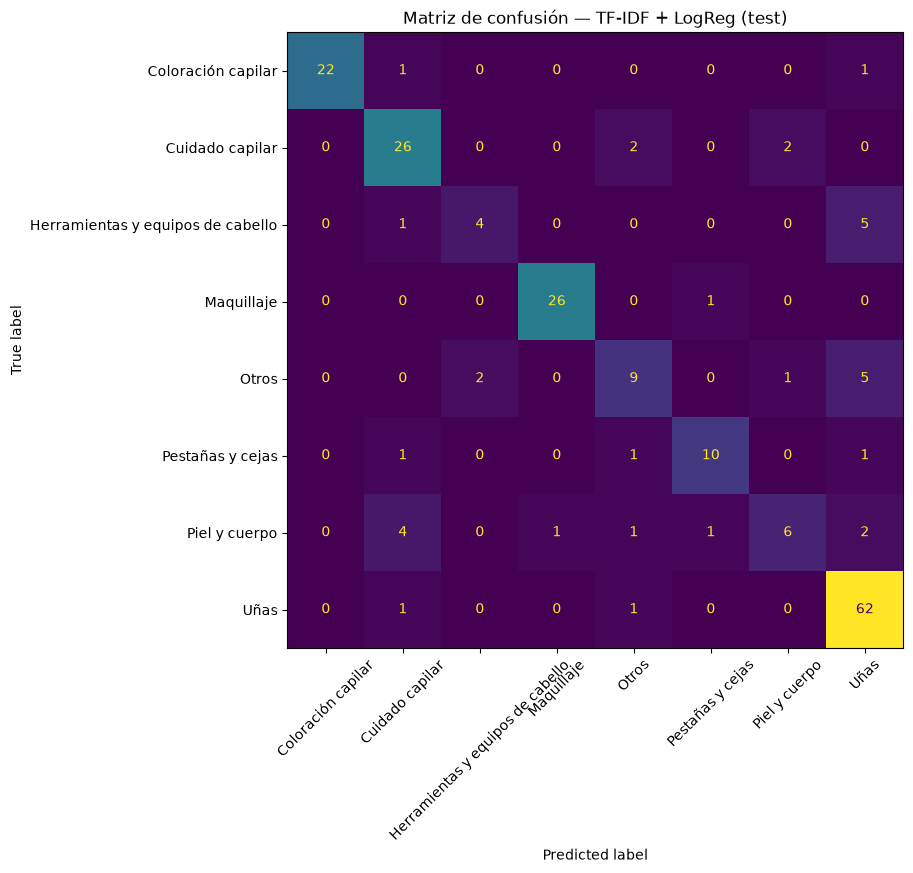

In [17]:
best = search_tfidf.best_estimator_
print(classification_report(y_test, best.predict(X_test), digits=2))
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_estimator(best, X_test, y_test, ax=ax, xticks_rotation=45, colorbar=False)
ax.set_title("Matriz de confusión — TF-IDF + LogReg (test)")
fig.savefig(FIG / "matriz_confusion.png", bbox_inches="tight")

**Lectura del test.** TF-IDF + LogReg: accuracy 0,825, F1-macro 0,75, F1-weighted 0,81,
AUC macro 0,97 y micro 0,98, muy cerca de lo estimado por validación cruzada (0,74–0,76):
el sesgo de selección de hiperparámetros no infló el resultado. La distancia entre
F1-macro (0,75) y F1-weighted (0,81) confirma que fallan las clases chicas:
- **Muy bien:** Coloración capilar (F1 0,96), Maquillaje (0,96), Uñas (0,89): tienen
  vocabulario y marcas propias.
- **Mal:** Herramientas y equipos de cabello (F1 0,50) y Piel y cuerpo (0,50). Las
  herramientas se confunden con Uñas (pinzas, limas, lámparas) y con Cuidado capilar;
  Piel y cuerpo se confunde con Cuidado capilar porque comparten palabras («mascarilla»,
  «crema», «aceite») que significan cosas distintas según sea para la cara o el cabello.
- Los AUC altos con F1 más bajo indican que el modelo **ordena** bien las clases pero el
  umbral de decisión (argmax) falla en las minoritarias.

## 9. Visualización con t-SNE (color = categoría)

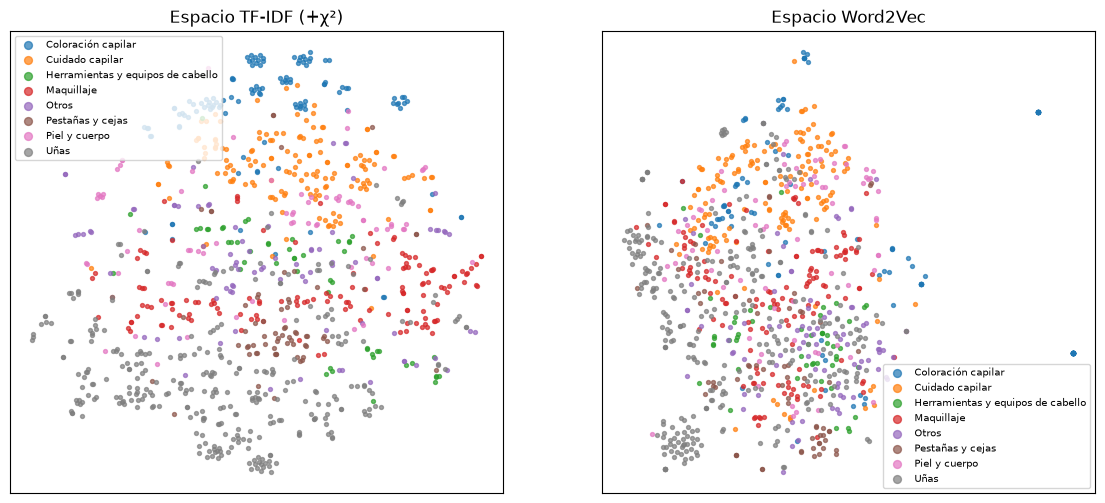

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
X_tfidf = search_tfidf.best_estimator_[:-1].transform(df["nombre"])
X_w2v = search_w2v.best_estimator_[:-1].transform(df["nombre"])
plot_tsne(X_tfidf, df["etiqueta"], axes[0], title="Espacio TF-IDF (+χ²)")
plot_tsne(X_w2v, df["etiqueta"], axes[1], title="Espacio Word2Vec")
fig.savefig(FIG / "tsne.png", bbox_inches="tight")

**Lectura.** En el espacio TF-IDF aparecen **islas compactas y de un solo color**
(líneas de producto como los tintes de una marca o los esmaltes de otra), mientras
«Otros», «Herramientas» y «Piel y cuerpo» quedan dispersas en el centro, mezcladas: es
la misma confusión que muestra la matriz. En el espacio Word2Vec las clases se
solapan mucho más; solo «Uñas» y parte de «Cuidado capilar» forman regiones propias.
t-SNE preserva vecindarios locales y no distancias globales, así que se lee la
separación de grupos, no la posición absoluta [5].

## 10. Aplicación al catálogo completo

El objetivo de negocio era categorizar los productos que quedaron en «General». Se
aplica el mejor modelo (TF-IDF + LogReg) a los **9 777 productos del catálogo
deduplicado que no forman parte de los 1 000 etiquetados**.

**Umbral de confianza.** La confianza de una predicción es la probabilidad que el
modelo asigna a la clase elegida. Antes de usarla hay que comprobar que significa
algo, y el umbral **no se elige mirando el test** (eso sería usar el test para tomar
una decisión): se usan predicciones *out-of-fold* sobre el 80 % de entrenamiento
(`cross_val_predict`, 5 folds estratificados) y se mide qué tan seguido acierta el
modelo cuando su confianza supera cada umbral.

In [19]:
best = search_tfidf.best_estimator_
proba_oof = cross_val_predict(
    best, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
    method="predict_proba", n_jobs=-1,
)
clases = np.sort(y_train.unique())
conf_oof = proba_oof.max(axis=1)
acierto_oof = clases[proba_oof.argmax(axis=1)] == y_train.to_numpy()
pd.DataFrame([
    {
        "umbral": u,
        "% que lo supera": round(100 * (conf_oof >= u).mean(), 1),
        "accuracy sobre esos": round(acierto_oof[conf_oof >= u].mean(), 3),
    }
    for u in (0.0, 0.5, 0.6, 0.7, 0.8, 0.9)
])

,umbral,% que lo supera,accuracy sobre esos
0,0.0,100.0,0.798
1,0.5,90.0,0.851
2,0.6,85.9,0.875
3,0.7,79.4,0.906
4,0.8,72.2,0.936
5,0.9,63.4,0.963


In [20]:
# Confirmación en el test (200 productos nunca vistos) con el umbral elegido.
UMBRAL = 0.8
proba_test = best.predict_proba(X_test)
conf_test = proba_test.max(axis=1)
acierto_test = best.classes_[proba_test.argmax(axis=1)] == y_test.to_numpy()
print(f"Test con confianza ≥ {UMBRAL}: {100 * (conf_test >= UMBRAL).mean():.1f} % de los productos, "
      f"accuracy {acierto_test[conf_test >= UMBRAL].mean():.3f}")

Test con confianza ≥ 0.8: 77.0 % de los productos, accuracy 0.968


revision
automática    7698
manual        2079
Name: count, dtype: int64

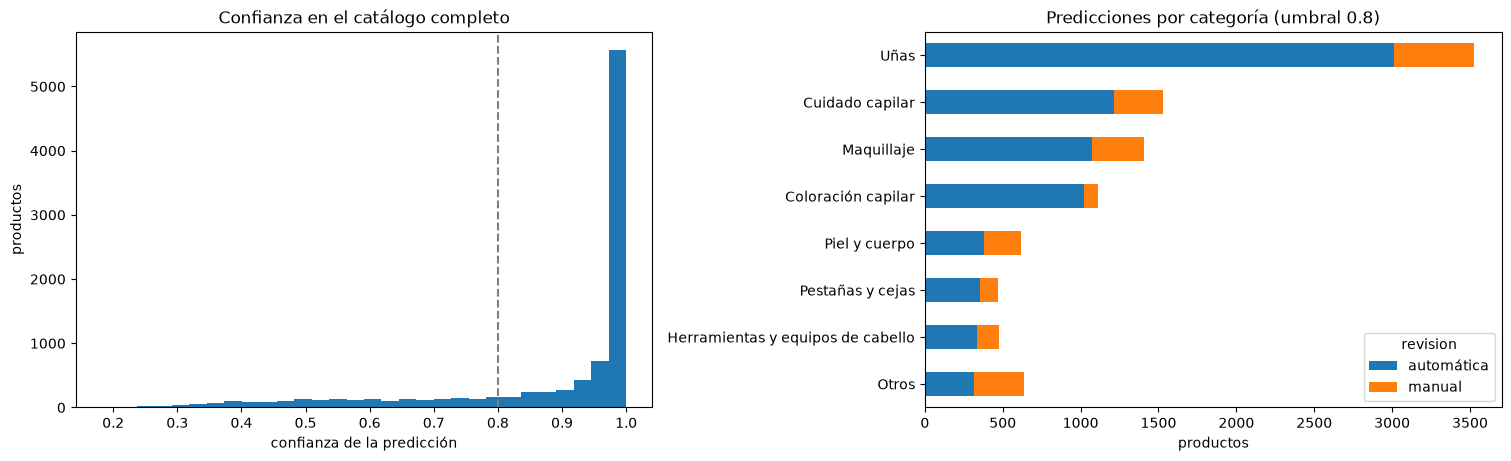

In [21]:
catalogo = pd.read_csv(ROOT / "data/processed/catalogo_sin_etiquetar.csv")
# Modelo final: mismos hiperparámetros, reentrenado con los 1 000 productos etiquetados.
modelo_final = clone(best).fit(df["nombre"], df["etiqueta"])
proba = modelo_final.predict_proba(catalogo["nombre"])
catalogo["prediccion"] = modelo_final.classes_[proba.argmax(axis=1)]
catalogo["confianza"] = proba.max(axis=1)
catalogo["revision"] = np.where(catalogo["confianza"] >= UMBRAL, "automática", "manual")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), layout="constrained")
catalogo["confianza"].plot.hist(bins=30, ax=axes[0])
axes[0].set_ylabel("productos")
axes[0].axvline(UMBRAL, ls="--", c="grey")
axes[0].set_xlabel("confianza de la predicción")
axes[0].set_title("Confianza en el catálogo completo")
pd.crosstab(catalogo["prediccion"], catalogo["revision"]).sort_values("automática").plot.barh(stacked=True, ax=axes[1])
axes[1].set_title(f"Predicciones por categoría (umbral {UMBRAL})")
axes[1].set_xlabel("productos")
axes[1].set_ylabel("")
fig.savefig(FIG / "catalogo_completo.png", bbox_inches="tight")
catalogo["revision"].value_counts()

In [22]:
# Ejemplos: las predicciones más seguras y las más dudosas.
cols = ["nombre", "prediccion", "confianza"]
pd.concat({
    "más seguras": catalogo.nlargest(8, "confianza")[cols].reset_index(drop=True),
    "más dudosas": catalogo.nsmallest(8, "confianza")[cols].reset_index(drop=True),
}, axis=1).round(2)

más seguras                       \
                                 nombre prediccion confianza   
0          ESMALTE GEL POLIS GLAM NAILS       Uñas       1.0   
1        ESMALTE EN GEL MASTER NAILS 02       Uñas       1.0   
2         ESMALTE MASTERNAILS GEL POLIS       Uñas       1.0   
3  ESMALTE GEL DE MASTER NAILS GELISH-6       Uñas       1.0   
4     ESMALTE GEL MASTER NAILS GELISH-7       Uñas       1.0   
5  ESMALTE GEL DE MASTER NAILS GELISH-1       Uñas       1.0   
6  ESMALTE GEL DE MASTER NAILS GELISH-3       Uñas       1.0   
7        ESMALTE EN GEL MASTER NAILS 07       Uñas       1.0   

                                         más dudosas                      \
                                              nombre          prediccion   
0                                     SAL DE LAVANDA                Uñas   
1                               BIGEN CASTAÑO OSCURO                Uñas   
2                  COLONIA L"ESSENCE VIOLETA SALVAJE       Piel y cuerpo   
3  THUYA FARBKA DO BRWI I RZĘS BRĄZ MARRON BROWN ...  Coloración capilar   
4                       RIZADOR TELA RULOS FLEXIBLES    Pestañas y cejas   
5      GOOD MOLECULES DISCOLORATION CORRECTING SERUM       Piel y cuerpo   
6                           TRIPACK RIZOS BIOESTETIC          Maquillaje   
7                      ENVASE PARA GUARDAR PEGAMENTO                Uñas   

             
  confianza  
0      0.18  
1      0.20  
2      0.20  
3      0.20  
4      0.22  
5      0.23  
6      0.23  
7      0.23

In [23]:
# Validación externa: productos que el personal de la tienda ya había categorizado en el
# ERP (todas categorías capilares). El modelo nunca vio esas etiquetas.
CAPILARES = {"Cuidado capilar", "Coloración capilar"}
ya = catalogo[catalogo["categoria_erp"] != "General"]
print(f"{len(ya)} productos con categoría previa en el ERP")
print(f"Predichos como capilares: {100 * ya['prediccion'].isin(CAPILARES).mean():.1f} %")
pd.crosstab(ya["categoria_erp"], ya["prediccion"]).loc[lambda t: t.sum(axis=1).sort_values(ascending=False).index].head(10)

534 productos con categoría previa en el ERP
Predichos como capilares: 93.3 %


prediccion,Coloración capilar,Cuidado capilar,Herramientas y equipos de cabello,Otros,Piel y cuerpo,Uñas
categoria_erp,,,,,,
Shampoo,3,101,0,0,1,0
Matizantes,2,59,0,0,2,1
Mascarilla,0,48,0,0,1,0
Ampollas,0,41,0,0,0,0
Acondicionador,0,40,0,0,0,0
Tratamiento,0,33,0,0,2,3
Tinte,22,11,0,0,0,0
Aceite,0,25,0,0,0,1
Crema De Peinar,0,17,0,0,0,0


**Lectura.**
- **Umbral.** Con predicciones out-of-fold, exigir confianza ≥ 0,8 deja el 72 % de los
  productos con un **93,6 % de acierto** (contra 79,8 % sin umbral). En el test, que no
  participó en la elección, ese umbral cubre el 77 % con un **96,8 %** de acierto: la
  confianza del modelo es informativa y el umbral generaliza.
- **Catálogo.** De los 9 777 productos, **7 698 (78,7 %) se categorizan
  automáticamente** y **2 079 (21,3 %) van a revisión manual**. Revisar 2 079 productos
  en vez de 9 777 reduce el trabajo manual en ~79 %.
- **Dónde duda.** «Otros» y «Piel y cuerpo» tienen la mayor proporción de revisión
  manual; «Coloración capilar» casi no la necesita. Coincide con el F1 por clase del
  test. Las predicciones más dudosas son productos realmente ambiguos o fuera de la
  taxonomía («SAL DE LAVANDA», «ENVASE PARA GUARDAR PEGAMENTO»).
- **Validación externa.** De los 534 productos que el personal de la tienda ya había
  categorizado (todos capilares), el modelo predijo como capilares el **93,3 %**, sin
  haber visto esas etiquetas. El error más frecuente está en la frontera prevista en la
  taxonomía: de los productos que el ERP tiene como «Tinte», 11 se predijeron como
  «Cuidado capilar».

## Bitácora de decisiones y ajustes

Ajustes hechos **después de ver los resultados**, con su motivo:

| # | Qué se vio | Ajuste | Por qué |
|---|---|---|---|
| 1 | Los clústeres de k-means agrupaban por marca (silhouette 0,02–0,04) | Taxonomía por *para qué sirve* el producto, definida a mano | Un clustering por marca no sirve como categoría de negocio |
| 2 | La primera grilla de χ² llegaba a k = 5000, pero cada fold tiene entre 3 760 y 4 674 n-gramas | Grilla de k bajada a 250–3500 | k > n° de features equivale a «todas» de forma implícita: la selección quedaba sin evaluar |
| 3 | Con la grilla de C hasta 10³, el óptimo de LogReg caía en el borde (C = 1000) | Grilla extendida hasta 10⁴ | Si el óptimo está en el borde no se sabe si hay uno mejor afuera; extendida, el óptimo (C ≈ 464) quedó en el interior |
| 4 | Con la grilla 250–3500, el mejor k cayó otra vez en el borde (3500): nunca se comparaba contra «sin selección» | Se agregó `all` a la grilla | Mismo criterio que con C; resultado: `all` es el mejor, χ² no aporta |
| 5 | Una revisión independiente señaló que el p de Wilcoxon es optimista (folds dependientes; mismos datos que el tuning) | Se agregó el t-test corregido de Nadeau–Bengio y se precisaron las limitaciones | El p corregido (≈ 4,3 × 10⁻⁶) es el defendible; la conclusión no cambia |
| 6 | «Extensiones y accesorios de cabello» llegó a 28 ejemplos | Fusionada en «Otros» | Regla fijada *antes* de etiquetar (mínimo 30); completarla a mano rompería la aleatoriedad |
| 7 | `RocCurveDisplay` cambió su API en sklearn 1.7 | Curvas ROC con `roc_curve` + matplotlib | Que el notebook corra igual en local (sklearn 1.9) y en Colab |
| 8 | El 10 × 10 tardó menos de 1 minuto | Se mantuvo 10 × 10 (no se bajó a 5 × 2) | Es la configuración recomendada por la rúbrica y el costo era bajo |
| 9 | Al agregar la aplicación al catálogo, el primer umbral de confianza se eligió mirando el test | Umbral elegido con predicciones out-of-fold del entrenamiento; el test solo lo confirma | Elegirlo con el test es usar el test para decidir: la cifra resultante sería optimista |

## 11. Conclusiones

1. **TF-IDF de n-gramas de caracteres + regresión logística supera a Word2Vec
   preentrenado + SVM** en este problema, con diferencia significativa (F1-macro 0,759
   vs 0,648 en 10 × 10 CV; t corregido p ≈ 4,3 × 10⁻⁶, Wilcoxon p ≈ 1,2 × 10⁻¹⁷) y en
   test (F1-macro 0,75 vs 0,58).
2. **La causa es la representación, no el clasificador.** El conocimiento general del
   idioma que trae Word2Vec no compensa que desconozca las marcas, que son las palabras
   más informativas del catálogo (11,6 % de palabras sin vector, casi todas marcas), ni
   las abreviaturas. Los n-gramas de caracteres capturan ambas cosas.
3. **El modelo tiene alta varianza y la curva de validación no se ha estabilizado**:
   etiquetar más productos es la mejora más rentable, y el etiquetado asistido la hace
   barata (0,4 % de corrección manual en esta muestra).
4. **Las clases difíciles son las de vocabulario compartido** (Herramientas, Piel y
   cuerpo, Otros). Para usarlo en la tienda conviene aplicar el modelo con un umbral de
   confianza y mandar a revisión manual los casos dudosos, en vez de categorizar todo
   automáticamente.
5. **Aplicado al catálogo, el modelo categoriza automáticamente el 78,7 %** de los
   9 777 productos (confianza ≥ 0,8, con ~94–97 % de acierto esperado) y deja 2 079 para
   revisión manual. Contra las categorías que la tienda ya tenía, coincide en el
   93,3 %. El trabajo manual se reduce en ~79 %.
6. **χ² no mejoró el modelo**: el mejor resultado fue sin selección (0,739) y la
   diferencia con k = 3500 es menor que la variación entre folds. Con regresión
   logística regularizada conviene conservar todos los n-gramas.

**Limitaciones:** una sola tienda; etiquetas de un solo revisor (sin acuerdo entre
anotadores); scores de CV repetida no independientes; la taxonomía es de esta tienda.

## 12. Referencias

[1] C. Cardellino, "Spanish Billion Words Corpus and Embeddings," 2016. [Online]. Available: https://crscardellino.ar/SBWCE/

[2] T. Mikolov, K. Chen, G. Corrado, and J. Dean, "Efficient estimation of word representations in vector space," arXiv:1301.3781, 2013.

[3] F. Pedregosa et al., "Scikit-learn: Machine learning in Python," *J. Mach. Learn. Res.*, vol. 12, pp. 2825–2830, 2011.

[4] F. Wilcoxon, "Individual comparisons by ranking methods," *Biometrics Bulletin*, vol. 1, no. 6, pp. 80–83, 1945.

[5] L. van der Maaten and G. Hinton, "Visualizing data using t-SNE," *J. Mach. Learn. Res.*, vol. 9, pp. 2579–2605, 2008.

[6] G. Salton and C. Buckley, "Term-weighting approaches in automatic text retrieval," *Inf. Process. Manage.*, vol. 24, no. 5, pp. 513–523, 1988.

[7] Anthropic, "Claude," 2026. Asistente usado para proponer etiquetas y escribir código (prompts en las celdas correspondientes).

[8] C. Nadeau and Y. Bengio, "Inference for the generalization error," *Mach. Learn.*, vol. 52, no. 3, pp. 239–281, 2003.